# 03 — V1: PhoWhisper-small + LoRA, trộn 4 nguồn

> Notebook trình bày, **không huấn luyện lại**. Mọi bảng và hình được tính từ file kết quả đã lưu trong `saved/`, chạy lại an toàn trên CPU. Log huấn luyện đã được rút gọn (bỏ thanh tiến độ, giữ mọi kết quả eval); bản đầy đủ nằm trong `ASR/notebooks/local` và `ASR/local/logs`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
S = next(p / 'saved' for p in [Path.cwd(), *Path.cwd().parents] if (p / 'saved/tables').is_dir())
T = S / 'tables'
def js(rel): return json.loads((S / rel).read_text(encoding='utf-8'))
def show_log(name): print((S / 'logs' / name).read_text(encoding='utf-8'))
def history(name): return js(f'runs/{name}_trainer_state.json')['log_history']
pd.set_option('display.precision', 2)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
C = {'Baseline 1': '#7E9C9B', 'Baseline 2': '#A9C2C0', 'V1': '#0F4E57', 'V2': '#1A6771', 'V-Final': '#FFB21A'}

**Kiến trúc.** Log-Mel 80 × 3.000 → Conv1D × 2 → Encoder 12 lớp → Decoder 12 lớp → token. LoRA gắn vào q, k, v, out_proj,
fc1, fc2 của encoder và decoder: `y = W·x + (α/r)·B·A·x`, W đóng băng, r = 32, α = 64, dropout 0,05.
**So với baseline:** thêm LoRA, huấn luyện trên 4 nguồn, nhãn chuẩn hóa cùng luật chấm.

In [2]:
print((S / 'configs/V1.yaml').read_text(encoding='utf-8'))

# V1 — PhoWhisper-small + LoRA on the 4-source mixture. Compare against B0 on the same dev split.
# Sized for a Colab T4 (16 GB). On OOM: lower batch_size and raise grad_accum (keep their product).
model:
  name: vinai/PhoWhisper-small
  lora:
    r: 32
    alpha: 64
    dropout: 0.05
    target_modules: [q_proj, k_proj, v_proj, out_proj, fc1, fc2]

train:
  epochs: 3
  batch_size: 16
  grad_accum: 2              # effective batch 32
  lr: 1.0e-3                 # typical for LoRA; full fine-tune would be ~1e-5
  warmup_ratio: 0.05
  fp16: true                 # T4 has no bf16
  gradient_checkpointing: true
  eval_steps: 500
  save_steps: 500            # must be a multiple of eval_steps (best-model tracking)
  save_total_limit: 2        # keeps best + latest on Drive
  logging_steps: 50
  num_workers: 2



**Lệnh đã chạy — huấn luyện V1** (chép từ `ASR/notebooks/local/03_V1.ipynb`, ô 5; chỉ để xem)

```python
if WORKFLOW == 'train':
    print('FULL V1 TRAINING: fresh base or resume local_v1; checkpoint saving is enabled.', flush=True)
    run_cli([RUNNER, 'train', EXP, '--run-id', 'local_v1'])
    CHECKPOINT = find_v1_checkpoint()
    print('Trained checkpoint:', CHECKPOINT)
else:
    print('Skipping training. Continue to the evaluation cells below.')
```

In [3]:
show_log('V1_train.txt')

===== 20261018_170854_868263.log
[INIT] mode=train experiment=V1_phowhisper_small_lora; importing PyTorch/ASR libraries...
{
  "python": "D:\\1.FPT_FALL26\\DPL - Deep Learning\\.venv-asr\\Scripts\\python.exe",
  "cuda": true,
  "versions": {
    "torch": "2.6.0+cu124",
    "transformers": "4.46.3",
    "peft": "0.13.2",
    "accelerate": "1.1.1",
    "datasets": "3.1.0"
  },
  …
}
[MODEL] Loading processor and weights; first use may download model files...
trainable params: 12,976,128 || all params: 254,711,040 || trainable%: 5.0945
[MODEL] Weights loaded.
[DATA] Loading TRAIN parquet and applying duration filters...
Exclude ViMedCSS/train: 10 empty-audio rows (duration <= 0): ['vimedcss:Med_CS-3625-10', 'vimedcss:Med_CS-3625-17', 'vimedcss:Med_CS-3625-19', 'vimedcss:Med_CS-3625-20', 'vimedcss:Med_CS-3625-5', 'vimedcss:Med_CS-3625-9', 'vimedcss:Med_CS-4072_1-1', 'vimedcss:Med_CS-4072_1-15', 'vimedcss:Med_CS-4072_1-17', 'vimedcss:Med_CS-4072_1-8']
[DATA] TRAIN: 29061 clips. Loading DEV.

## Đường cong loss và WER (từ `trainer_state.json`)

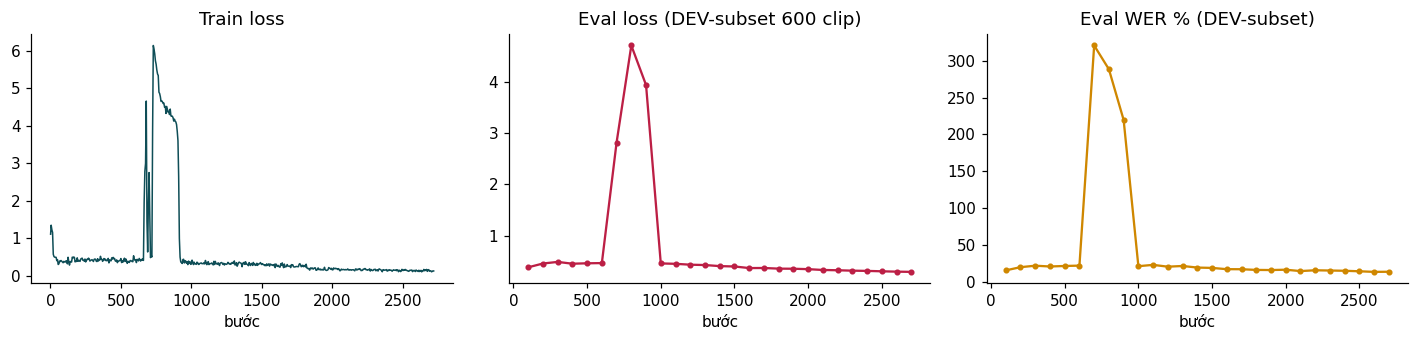

Loss đỉnh 6.14 ở bước 730 (grad_norm 358); eval loss cao nhất 4.70 ở bước 800


In [4]:
h = history('V1')
tr = pd.DataFrame([x for x in h if 'loss' in x and 'step' in x]); ev = pd.DataFrame([x for x in h if 'eval_wer' in x])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].plot(tr.step, tr.loss, lw=1, color='#0F4E57'); ax[0].set_title('Train loss')
ax[1].plot(ev.step, ev.eval_loss, marker='o', ms=3, color='#BC1F45'); ax[1].set_title('Eval loss (DEV-subset 600 clip)')
ax[2].plot(ev.step, 100 * ev.eval_wer, marker='o', ms=3, color='#CF8700'); ax[2].set_title('Eval WER % (DEV-subset)')
for a in ax: a.set_xlabel('bước')
plt.tight_layout(); plt.show()
pk = tr.loc[tr.loss.idxmax()]
print(f"Loss đỉnh {pk.loss:.2f} ở bước {int(pk.step)} (grad_norm {pk.grad_norm:.0f}); eval loss cao nhất {ev.eval_loss.max():.2f} ở bước {int(ev.loc[ev.eval_loss.idxmax(), 'step'])}")

## Tín hiệu cải thiện so với 2 baseline (DEV chính thức)

In [5]:
def dev_row(name):
    m = js(f'metrics/{name}.json'); o, s = m['overall'], m['by_source']
    return {'WER %': 100 * o['wer'], 'CER %': 100 * o['cer'], 'Recall thuật ngữ %': 100 * o.get('cs_term_recall', float('nan')),
            **{k: 100 * s[k]['wer'] for k in ['ViMedCSS', 'VietMed', 'FLEURS', 'VIVOS']}}
DEV = pd.DataFrame({'Baseline 1': dev_row('Baseline1_dev'), 'Baseline 2': dev_row('Baseline2_dev'), 'V1': dev_row('V1_dev')}).T
DEV

,WER %,CER %,Recall thuật ngữ %,ViMedCSS,VietMed,FLEURS,VIVOS
Baseline 1,24.73,19.25,12.96,28.36,25.87,10.89,0.42
Baseline 2,58.75,46.35,16.05,46.45,73.92,25.61,20.45
V1,18.48,14.36,71.26,16.10,21.80,11.12,6.92


In [6]:
d = DEV.loc['V1'] - DEV.loc['Baseline 1']
print('V1 so với Baseline 1 (điểm %):'); print(d.round(2).to_string())

V1 so với Baseline 1 (điểm %):
WER %                 -6.25
CER %                 -4.89
Recall thuật ngữ %    58.30
ViMedCSS             -12.27
VietMed               -4.06
FLEURS                 0.23
VIVOS                  6.50


## Phân tích lỗi của V1 (toàn bộ DEV, cùng phương pháp phân loại với báo cáo)

In [7]:
import collections, jiwer
pred = pd.read_json(S / 'predictions/V1_dev.jsonl', lines=True)
pred = pred[pred.ref != ''].reset_index(drop=True)
subs, recs = collections.Counter(), []
for i, r in pred.iterrows():
    o = jiwer.process_words(r.ref, r.hyp); rw, hw = r.ref.split(), r.hyp.split(); al = o.alignments[0]
    for ch in al:
        if ch.type == 'substitute':
            for a, b in zip(range(ch.ref_start_idx, ch.ref_end_idx), range(ch.hyp_start_idx, ch.hyp_end_idx)):
                subs[(rw[a], hw[b])] += 1
    edge = sum(max(c.ref_end_idx - c.ref_start_idx, c.hyp_end_idx - c.hyp_start_idx) for c in (al[0], al[-1]) if c.type in ('delete', 'insert')) if al else 0
    recs.append(dict(source=r.source, n=max(1, len(rw)), S=o.substitutions, D=o.deletions, I=o.insertions, edge=edge))
err = pd.DataFrame(recs); err['errors'] = err.S + err.D + err.I
cat = pd.Series('thay thế rải rác', index=err.index)
cat[err.D > err.S + err.I] = 'xóa là chính (mất đoạn)'
cat[err.I > err.S + err.D] = 'chèn là chính (thừa/lặp)'
cat[(err.edge >= 3) & (err.edge >= .4 * err.errors)] = 'lệch biên đầu/cuối clip'
cat[err.errors == 0] = 'đúng hoàn toàn'
err['category'] = cat
total = err.errors.sum()
by_cat = err[err.errors > 0].groupby('category').agg(clip=('n', 'size'), loi=('errors', 'sum')).assign(pct=lambda x: 100 * x.loi / total).sort_values('loi', ascending=False)
print(f"{total:,} lỗi từ trên {len(err):,} clip; {int((err.errors == 0).sum()):,} clip đúng hoàn toàn".replace(',', '.'))
by_cat

23.645 lỗi từ trên 5.168 clip; 379 clip đúng hoàn toàn


,clip,loi,pct
category,,,
thay thế rải rác,2498,11359,48.04
lệch biên đầu/cuối clip,1605,9834,41.59
xóa là chính (mất đoạn),414,1239,5.24
chèn là chính (thừa/lặp),272,1213,5.13


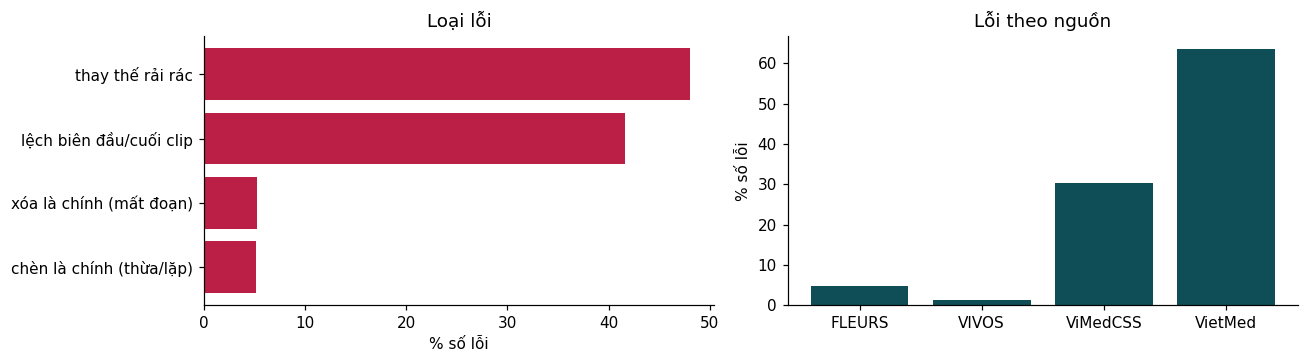

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].barh(by_cat.index[::-1], by_cat.pct[::-1], color='#BC1F45'); ax[0].set_xlabel('% số lỗi'); ax[0].set_title('Loại lỗi')
src = err.groupby('source').errors.sum() / total * 100
ax[1].bar(src.index, src.values, color='#0F4E57'); ax[1].set_ylabel('% số lỗi'); ax[1].set_title('Lỗi theo nguồn')
plt.tight_layout(); plt.show()

### Cặp từ hay nhầm (thay cho Confusion Matrix: ASR không có lớp cố định)

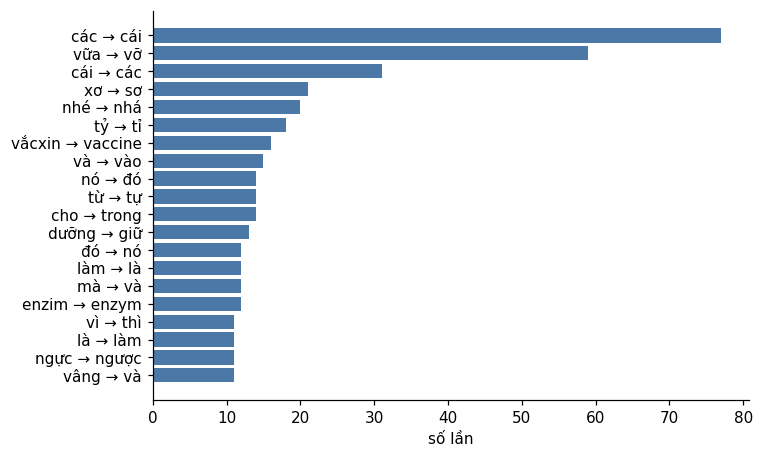

In [9]:
top = subs.most_common(20)
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh([f'{a} → {b}' for (a, b), _ in top][::-1], [c for _, c in top][::-1], color='#4C78A8'); ax.set_xlabel('số lần'); plt.show()

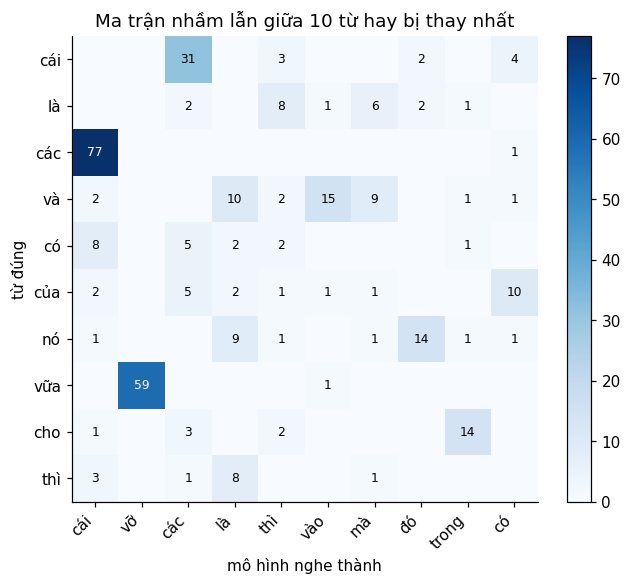

In [10]:
import numpy as np
refs = [w for w, _ in collections.Counter(a for (a, _), c in subs.items() for _ in range(c)).most_common(10)]
hyps = [w for w, _ in collections.Counter(b for (a, b), c in subs.items() if a in refs for _ in range(c)).most_common(10)]
M = np.array([[subs.get((a, b), 0) for b in hyps] for a in refs])
fig, ax = plt.subplots(figsize=(7, 5.5)); im = ax.imshow(M, cmap='Blues')
ax.set_xticks(range(len(hyps)), hyps, rotation=45, ha='right'); ax.set_yticks(range(len(refs)), refs)
for i in range(len(refs)):
    for j in range(len(hyps)):
        if M[i, j]: ax.text(j, i, M[i, j], ha='center', va='center', fontsize=8, color='white' if M[i, j] > M.max() / 2 else 'black')
ax.set_xlabel('mô hình nghe thành'); ax.set_ylabel('từ đúng'); ax.set_title('Ma trận nhầm lẫn giữa 10 từ hay bị thay nhất'); plt.colorbar(im); plt.show()

### Thuật ngữ y khoa: đã gặp và chưa gặp khi huấn luyện

In [11]:
train_terms = js('runs/train_terms_official.json')
occ, word, sub = collections.Counter(), collections.Counter(), collections.Counter()
for r in pred.itertuples():
    w, seen = r.hyp.split(), collections.Counter()
    for t in r.terms:
        tw = t.split(); seen[t] += 1
        k = sum(w[i:i + len(tw)] == tw for i in range(len(w) - len(tw) + 1))
        occ[t] += 1; word[t] += seen[t] <= k; sub[t] += t in r.hyp
tm = pd.DataFrame({'lượt': occ, 'đúng nguyên từ': word, 'đúng chuỗi con': sub}).fillna(0)
n = tm['lượt'].sum()
print(f"Recall thuật ngữ: khớp chuỗi con {100 * tm['đúng chuỗi con'].sum() / n:.2f}% (bằng số trong metrics.json), "
      f"khớp nguyên từ {100 * tm['đúng nguyên từ'].sum() / n:.2f}% (chặt hơn: 'vaccin' trong 'vaccine' không được tính)")
unseen = [t for t in tm.index if t not in train_terms]
print(f"Thuật ngữ trong DEV chưa từng có trong Train chính thức: {len(unseen)} loại")
tm.assign(sai=tm['lượt'] - tm['đúng chuỗi con']).sort_values('sai', ascending=False).head(10)

Recall thuật ngữ: khớp chuỗi con 71.26% (bằng số trong metrics.json), khớp nguyên từ 64.04% (chặt hơn: 'vaccin' trong 'vaccine' không được tính)
Thuật ngữ trong DEV chưa từng có trong Train chính thức: 0 loại


,lượt,đúng nguyên từ,đúng chuỗi con,sai
enzim,15,2,2,13
gen,53,44,44,9
inulin,23,14,14,9
cafein,8,0,0,8
glucagon,7,0,0,7
hocmon,5,0,0,5
virus,90,84,85,5
caffein,14,0,9,5
hormone,19,15,15,4
oxy,51,47,47,4


### Ví dụ sai nhiều nhất (câu 6–28 từ)

In [12]:
mix = pred.join(err[['S', 'D', 'I', 'errors', 'category']]).assign(wer=lambda x: x.errors / x.ref.str.split().str.len())
ex = mix[mix.ref.str.split().str.len().between(6, 28)].sort_values('wer', ascending=False).groupby('source').head(2)
pd.set_option('display.max_colwidth', 120); ex[['source', 'category', 'wer', 'ref', 'hyp']]

,source,category,wer,ref,hyp
2092,VietMed,lệch biên đầu/cuối clip,3.42,chuyển lạnh thì là nó rất là buốt và nó rất là đau nhức không thể làm được cái,cái tuyến thừa tuyến thừa tuyến thừa tuyến thừa tuyến thừa tuyến thừa tuyến thừa tuyến thừa tuyến thừa tuyến thừa tu...
2859,VietMed,chèn là chính (thừa/lặp),1.86,nói là cắn chích ngừa có hiệu,chứ còn mà mình nói là đạc tránh và chất lượng không có thể bỏ ra
3853,ViMedCSS,lệch biên đầu/cuối clip,1.83,glanzmann của ta vào năm 18,hoặc là có thể là một cái phản ứng người ta
4724,ViMedCSS,thay thế rải rác,1.45,it prompts your muscle and fat cells to let glucose in and jump starts the conversion of sugar to energy,nó tạo ra các kháng năng và các máu nạp để cho thêm glucose và bóng ra các kháng năng của nước từ thành thành thành ...
387,FLEURS,thay thế rải rác,0.56,nước tràn qua đê kéo rộng đến 100 feet,nước chèn qua đê kéo gộng đến một chân phít
279,FLEURS,thay thế rải rác,0.50,có thể đổi tiền ở ngân hàng duy nhất trên đảo tọa lạc trên phố stanley đối diện với tiệm fic west,có thể đói tiền ở ngân hàng duy nhất trên đảo tọa là tranh phố stent lay đối với hiện tiện f i c west
113,VIVOS,thay thế rải rác,0.44,dạ con bé láu liến con trông khoẻ đẹp thế này nhưng thấp bé nhất lớp,dạ con bí léo luyến con trong khuỷ đề thế này nhưng thấp nhất lớp
168,VIVOS,thay thế rải rác,0.35,trung tá cử buồn như anh nông dân mất trâu cày cứ suốt ngày đi ra đi vào thẫn thờ,trông tá cử buồn như anh nông giăng mắt rau cà cứ suốt ngày đưa ra đi vào thẳng thờ
